# 04 · Improving the four classifiers

The original experiment in notebook 03 is our baseline. This notebook tests a bounded set of improvements on **2025 only**. It never loads Q1/Q2-2026 outcomes. April–June 2026 is reserved for notebook 05 after these choices are frozen.

We retain Logistic Regression, KNN, RBF SVM and Random Forest. Selection uses mean average precision (AP) across three chronological validation blocks. F1 remains the main warning-threshold rule; F0.5 is a secondary precision-prioritizing comparison, not a replacement for F1.

All candidate findings here are development results. A higher development score is an improvement hypothesis until the fresh test confirms it.

**Review and rerun note:** the saved outputs show the completed experiment. Once notebook 05 has opened the fresh test, this notebook deliberately stops at its first cell to keep this experiment frozen. Further tuning belongs in a new experiment; notebook 05 can replay the unchanged scoring procedure.

In [1]:
from pathlib import Path
import site
if site.ENABLE_USER_SITE:
    site.addsitedir(site.getusersitepackages())
import sys, json, hashlib
from datetime import datetime, timezone
from time import perf_counter
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import average_precision_score, precision_recall_curve, confusion_matrix, roc_auc_score

ROOT=Path.cwd().resolve()
if ROOT.name=='notebooks': ROOT=ROOT.parent
if (ROOT/'departure-delay-classification/config/project.json').exists(): ROOT/= 'departure-delay-classification'
sys.path.insert(0,str(ROOT/'scripts'))
from improvement_features import (TIME_FEATURES, FLIGHT_FEATURES, WEATHER_NEW, WEATHER_BASE,
    load_weather, add_time, add_weather, add_histories, add_traffic)
CONFIG=json.loads((ROOT/'config/project.json').read_text())
PREP=json.loads((ROOT/'reports/preparation_manifest.json').read_text())['feature_engineering']
BASE_SELECTION=json.loads((ROOT/'reports/model_selection.json').read_text())
OUT=ROOT/'reports/improvements';OUT.mkdir(exist_ok=True)
if any((OUT/name).exists() for name in ['test_results.json','test_access.json']):
    raise RuntimeError('The new test has already been evaluated. Keep this frozen experiment; discuss a new version before tuning again.')
SEED=42
RUN_ID=datetime.now(timezone.utc).strftime('improved_%Y%m%dT%H%M%S%fZ')
A0=PREP['feature_sets']['A'];B0=PREP['feature_sets']['B']
CATEGORIES=['airline','origin','destination','weekday']
NAMES={'logistic_regression':'Logistic Regression','knn':'KNN','svm':'RBF SVM','random_forest':'Random Forest'}
PACKAGES={p:version(p) for p in ['numpy','pandas','scikit-learn','pyarrow','matplotlib','seaborn','joblib']}
sns.set_theme(style='whitegrid',palette=['#247BA0','#E08D3C','#5C946E','#8465A0'])
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
def table(x,**kw): print(x.to_string(**kw))
def plot(): plt.tight_layout();plt.show()
def sha(path):
    with path.open('rb') as f:return hashlib.file_digest(f,'sha256').hexdigest()
def save_json(path,value): path.write_text(json.dumps(value,indent=2,allow_nan=False)+'\n')
def fingerprint(frame):
    text='\n'.join(frame['flight_id'].astype(str).sort_values())
    return hashlib.sha256(text.encode()).hexdigest()
protected=json.loads((OUT/'baseline_fingerprints.json').read_text())
assert all(sha(ROOT/p)==v for p,v in protected.items()),'An existing baseline input changed; review before continuing.'
print('Improvement run:',RUN_ID)
table(pd.Series(PACKAGES,name='version').to_frame())

Improvement run: improved_20261018T204129454478Z
             version
numpy          2.5.1
pandas         3.0.3
scikit-learn   1.9.0
pyarrow       20.0.0
matplotlib    3.11.1
seaborn       0.13.2
joblib         1.5.3


## Declare the experiment before scoring candidates

Three folds train on January–March, January–June and January–September; their next three months are validation. Each fold has a shared 20,000-flight fitting sample and 5,000 validation flights. A nested 40,000-flight sample adds 20,000 different flights for the later learning-curve comparison. Month × outcome stratification preserves natural proportions; it does not balance the classes.

The latest fold reuses notebook 03's exact cohorts. All four models and feature variants use the same flights. Whole dates stay on one side of a fold boundary. No shuffled cross-validation is used.

We first tune the original A/B inputs. We then compare a predeclared sequence of feature packages, holding the selected model settings fixed. One common package and one common sample size are chosen by mean AP across the four models (and both A/B sets for sample size). Ties retain the simpler package/smaller sample. This separates the measured tuning, feature and sample-size changes, while acknowledging development-set selection uncertainty.

Historical inputs use a walk-forward simulation: a later validation flight can use outcomes from earlier validation days after the seven-day lag. The classifier stays fixed within each fold. This requires the same stated outcome-feed availability assumption as the original project.

In [2]:
FOLDS=[('Apr–Jun','2025-03-31','2025-04-01','2025-06-30'),
       ('Jul–Sep','2025-06-30','2025-07-01','2025-09-30'),
       ('Oct–Dec','2025-09-30','2025-10-01','2025-12-31')]
BASE_CHOICES={(r['model_id'],r['feature_set']):r for r in BASE_SELECTION['choices']}
SEARCH={
 'logistic_regression': [('separate',{'C':c}) for c in [.01,.03,.1,.3,1.]],
 'knn':[('separate',{'n_neighbors':k,'weights':'distance','metric':metric})
        for k,metric in [(31,'euclidean'),(61,'euclidean'),(101,'euclidean'),(61,'manhattan')]]
       +[('separate',{'n_neighbors':61,'weights':'uniform','metric':'euclidean','drop_duration':True})],
 'svm':[('separate',{'C':c,'gamma':g}) for c in [.1,1.,10.] for g in [.001,.01,.1]],
 'random_forest':[('separate',{'max_depth':d,'min_samples_leaf':leaf,'max_features':.5,'class_weight':None})
                  for d in [8,16,None] for leaf in [10,30]]
                 +[('separate',{'max_depth':16,'min_samples_leaf':10,'max_features':.5,'class_weight':'balanced'})]}
# Each grid also includes that model/set's original winning recipe as the first candidate.
PACKAGES_FEATURES={'original':[], 'time':TIME_FEATURES,
                  'time_flight':TIME_FEATURES+FLIGHT_FEATURES,
                  'time_flight_weather':TIME_FEATURES+FLIGHT_FEATURES+WEATHER_NEW}
PLAN={'run_id':RUN_ID,'folds':FOLDS,'training_sizes':[20000,40000],'validation_rows':5000,
 'seed':SEED,'strata':['month','delayed_departure'],'nested_samples':True,
 'search':SEARCH,'baseline_choices':BASE_SELECTION['choices'],
 'feature_packages':PACKAGES_FEATURES,'A':A0,'B':B0,
 'history':{'days':28,'lag_days':7,'prior_strength':20,'flight_group':['origin','airline','flight_number']},
 'weather':{'buffer_minutes':20,'max_age_minutes':180,'window':'3 hours ending at latest matched report'},
 'selection':'highest unweighted mean fold AP; common feature package by mean across four models',
 'sample_selection':'highest mean AP across models, folds and A/B; tie -> 20k',
 'threshold':'F1 on latest validation fold; F0.5 secondary only; highest threshold breaks ties',
 'final_fit':'2025 only, same sample IDs across all models and A/B',
 'fresh_test':'2026-04-01 through 2026-06-30; sampled 10000; not loaded here',
 'excluded':['aircraft rotation','same-day outcome state','forecast weather','target encoding','SMOTE'],
 'packages':PACKAGES}
PROTOCOL_SHA=hashlib.sha256(json.dumps(PLAN,sort_keys=True).encode()).hexdigest()
save_json(OUT/'protocol.json',dict(PLAN,protocol_sha256=PROTOCOL_SHA))
print('Declared tuning fits:',sum(len(v)+1 for v in SEARCH.values())*2*len(FOLDS))
table(pd.DataFrame(FOLDS,columns=['validation','training_end','validation_start','validation_end']),index=False)

Declared tuning fits: 180
validation training_end validation_start validation_end
   Apr–Jun   2025-03-31       2025-04-01     2025-06-30
   Jul–Sep   2025-06-30       2025-07-01     2025-09-30
   Oct–Dec   2025-09-30       2025-10-01     2025-12-31


In [3]:
features=pd.read_parquet(ROOT/PREP['output'],filters=[('flight_date','>=',pd.Timestamp('2025-01-01')),('flight_date','<',pd.Timestamp('2026-01-01'))])
assert len(features)==938417 and features['flight_id'].is_unique

def sample(frame,n,seed=SEED):
    frame=frame.sort_values('flight_id')
    strata=frame['month'].astype(str)+'|'+frame['delayed_departure'].astype(str)
    ix,_=train_test_split(frame.index,train_size=n,stratify=strata,random_state=seed)
    return frame.loc[ix].sort_values('flight_id')

def nested(population,first=None):
    small=sample(population,20000) if first is None else first
    extra=sample(population.loc[~population['flight_id'].isin(small['flight_id'])],20000,SEED+1)
    return {20000:small['flight_id'].tolist(),40000:sorted(small['flight_id'].tolist()+extra['flight_id'].tolist())}

cohorts={};cohort_rows=[]
for fold,end,start,stop in FOLDS:
    population=features.loc[features['flight_date'].le(end)]
    vp=features.loc[features['flight_date'].between(start,stop)]
    first=population.loc[population['model_sample']] if fold=='Oct–Dec' else None
    ids=nested(population,first)
    val=vp.loc[vp['model_sample']] if fold=='Oct–Dec' else sample(vp,5000)
    cohorts[fold]={'train':ids,'validation':val['flight_id'].tolist()}
    assert len(val)==5000 and set(ids[20000]).issubset(ids[40000])
    assert set(ids[40000]).isdisjoint(val['flight_id'])
    cohort_rows.append({'fold':fold,'train_population':len(population),'train20k':20000,
                       'train40k':40000,'validation':len(val),'validation_prevalence':float(val['delayed_departure'].mean())})
final_ids=nested(features,features.loc[features['refit_sample']])
needed=set(final_ids[40000])
for c in cohorts.values(): needed.update(c['train'][40000]);needed.update(c['validation'])
working=features.loc[features['flight_id'].isin(needed)].copy().reset_index(drop=True)
del features
assert working['flight_date'].lt('2026-01-01').all()
table(pd.DataFrame(cohort_rows),index=False)
print('Distinct development flights needed in memory:',len(working))

   fold  train_population  train20k  train40k  validation  validation_prevalence
Apr–Jun            209171     20000     40000        5000                 0.2764
Jul–Sep            450239     20000     40000        5000                 0.2704
Oct–Dec            698670     20000     40000        5000                 0.2532
Distinct development flights needed in memory: 149379


## Add a small number of defensible variables

Time features add a second daily/annual harmonic and airport × clock interactions. Flight-number history uses earlier flights with the same origin, airline and flight number: a 28-day window ending seven days before the cutoff, smoothed toward origin history with the existing strength of 20. It never uses the current flight's outcome.

Weather additions use saved dew point, wind direction and earlier observations. Wind components are zero for calm wind; unknown directions stay missing otherwise. Prior-weather statistics cover three hours ending at the latest qualifying report. Their counts describe available reports, not complete continuous weather. Precipitation totals are **not summed**, since reporting periods overlap. Unknown precipitation stays unknown. No new external predictor source is required.

Traffic normalization, pressure, destination weather and additional operational feeds are deferred; they are not necessary to complete this controlled first improvement round.

Reconstructed B fields match the reviewed handoff on all 200 audit flights.
                           missing_fraction  unique_nonmissing
departure_sin2                     0.000000               1023
departure_cos2                     0.000000               1008
month_sin2                         0.000000                 12
month_cos2                         0.000000                  8
atl_departure_sin                  0.000000                990
atl_departure_cos                  0.000000                998
atl_departure_sin2                 0.000000                977
atl_departure_cos2                 0.000000                982
ord_departure_sin                  0.000000                956
ord_departure_cos                  0.000000                957
ord_departure_sin2                 0.000000                937
ord_departure_cos2                 0.000000                946
dfw_departure_sin                  0.000000                960
dfw_departure_cos                  0.00000

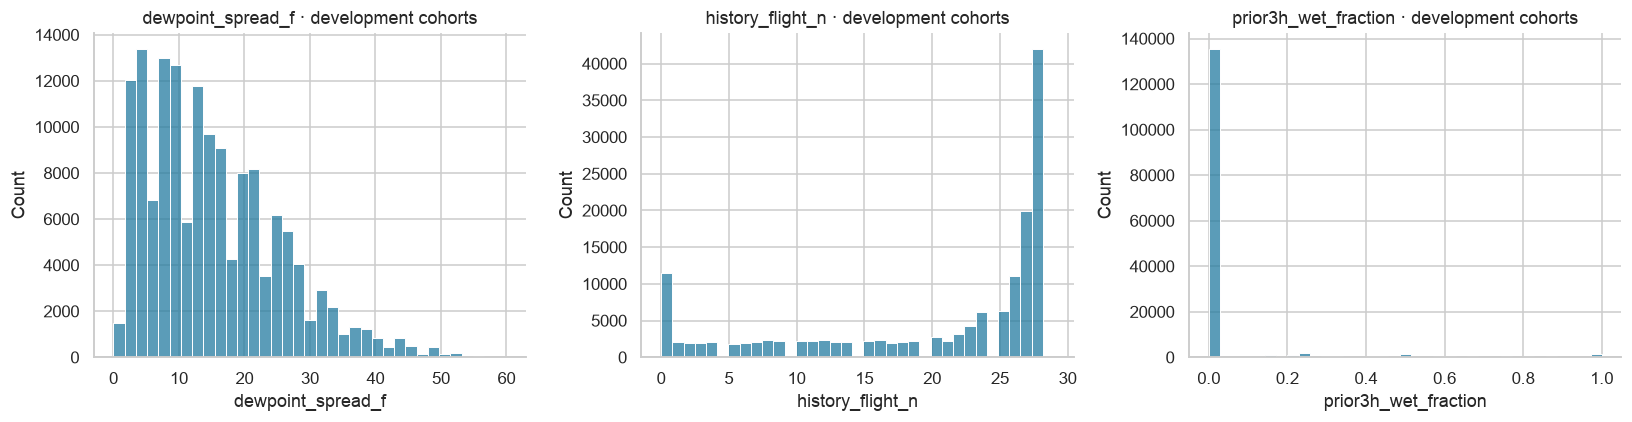

In [4]:
weather,weather_audit=load_weather(ROOT,[2025],CONFIG['weather_quality']['excluded_station_times'])
context=pd.read_parquet(ROOT/'data/processed/flights_clean.parquet',columns=[
 'flight_id','flight_date','origin','airline','destination','flight_number','label_eligible',
 'delayed_departure','departure_outcome_event_utc','scheduled_departure_utc','scheduled_departure_minutes'],
 filters=[('flight_date','<',pd.Timestamp('2026-01-01'))])
events=context.loc[context['label_eligible']].copy()
# Flight number was retained in the clean table, not the compact feature handoff.
for column in ['flight_number','scheduled_departure_minutes']:
    working[column]=working['flight_id'].map(context.set_index('flight_id')[column])
assert working['flight_number'].notna().all()
working=add_time(add_histories(add_weather(working,weather),events))
# Reconstruct the reviewed B recipe on 200 flights, independently of its saved values.
check=working.head(200).copy()
rebuilt=add_traffic(add_histories(add_weather(check,weather,base=True),events,base=True),context)
for column in [*WEATHER_BASE,'weather_age_minutes','history_origin_rate','history_airline_origin_rate',
               'history_route_rate','history_origin_n','history_airline_origin_n','history_route_n',
               'airport_scheduled_departures_prior_60m']:
    np.testing.assert_allclose(check[column].to_numpy(dtype=float),rebuilt[column].to_numpy(dtype=float),equal_nan=True,rtol=0,atol=1e-12)
print('Reconstructed B fields match the reviewed handoff on all 200 audit flights.')
working=working.set_index('flight_id',drop=False)
new_columns=TIME_FEATURES+FLIGHT_FEATURES+WEATHER_NEW
profile=pd.DataFrame({'missing_fraction':working[new_columns].isna().mean(),
                      'unique_nonmissing':working[new_columns].nunique()})
table(profile)
fig,axes=plt.subplots(1,3,figsize=(15,4))
for column,ax in zip(['dewpoint_spread_f','history_flight_n','prior3h_wet_fraction'],axes):
    sns.histplot(data=working,x=column,bins=35,ax=ax);ax.set_title(column+' · development cohorts')
plot()
del rebuilt,check,context,events,weather

## Compare scaling and tuning on matched flights

The original recipe standardizes continuous measurements, 0/1 flags and automatic missing indicators together. The alternative scales **continuous values only**, keeps binary and missing indicators at 0/1, and still learns imputation/scaling from fitting rows only. Categorical variables retain one-hot encoding.

Each grid starts with the original winning recipe, so a larger search cannot exclude the benchmark. KNN explores larger neighbourhoods and Manhattan distance; its final compact variant also drops redundant scheduled duration. SVM tunes C and gamma jointly. RF varies feature subsampling, depth, leaf support and class weights. These are bounded comparisons, not an exhaustive optimization.

Parameter meanings: lower **C** means stronger regularization; larger **k** averages over more neighbours; smaller SVM **gamma** gives a broader kernel; larger RF **min_samples_leaf** requires more training flights per terminal leaf.

In [5]:
BINARY=[c for c in B0+new_columns if c.endswith('_no_history')]+[
 'precip_trace','no_ceiling_reported','cloud_coverage_missing','rain_reported','frozen_precip_reported',
 'fog_or_mist_reported','thunder_reported','condition_codes_missing','ceiling_height_missing',
 'weather_report_missing','freezing_wet']
COVERED=CONFIG['preprocessing']['explicit_missingness_covered_columns']
ESTIMATORS={
 'logistic_regression':LogisticRegression(max_iter=3000,random_state=SEED),
 'knn':KNeighborsClassifier(algorithm='brute',n_jobs=2),
 'svm':SVC(kernel='rbf',cache_size=512,random_state=SEED),
 'random_forest':RandomForestClassifier(n_estimators=200,max_features='sqrt',class_weight='balanced',random_state=SEED,n_jobs=2)}

def columns_for(feature_set,package):
    return ((A0+([c for c in TIME_FEATURES] if package!='original' else [])) if feature_set=='A'
            else B0+PACKAGES_FEATURES[package])

def make_pipeline(model_id,columns,recipe,params):
    params=params.copy();drop_duration=params.pop('drop_duration',False)
    columns=[c for c in columns if not(drop_duration and c=='scheduled_duration_minutes')]
    numeric=[c for c in columns if c not in CATEGORIES]
    scale=model_id!='random_forest';trans=[]
    if recipe=='original':
        groups=[('numeric',[c for c in numeric if c not in COVERED],True),
                ('explicit',[c for c in numeric if c in COVERED],False)]
        for name,cols,indicators in groups:
            if not cols: continue
            steps=[('imputer',SimpleImputer(strategy='median',add_indicator=indicators,keep_empty_features=True))]
            if scale:steps.append(('scaler',StandardScaler()))
            trans.append((name,Pipeline(steps),cols))
    else:
        continuous=[c for c in numeric if c not in BINARY]
        flags=[c for c in numeric if c in BINARY]
        steps=[('imputer',SimpleImputer(strategy='median',keep_empty_features=True))]
        if scale:steps.append(('scaler',StandardScaler()))
        if continuous:trans.append(('continuous',Pipeline(steps),continuous))
        if flags:trans.append(('binary',SimpleImputer(strategy='constant',fill_value=0,keep_empty_features=True),flags))
        missing=[c for c in numeric if c not in COVERED]
        if missing:trans.append(('missing',MissingIndicator(features='all',error_on_new=False),missing))
    cat=Pipeline([('imputer',SimpleImputer(strategy='constant',fill_value='Unknown',keep_empty_features=True)),
                  ('encoder',OneHotEncoder(handle_unknown='ignore',sparse_output=True))])
    trans.append(('category',cat,CATEGORIES))
    return Pipeline([('preprocess',ColumnTransformer(trans,sparse_threshold=1.0)),
                     ('classifier',clone(ESTIMATORS[model_id]).set_params(**params))])

def scores(model,frame,columns):
    if isinstance(model.named_steps['classifier'],SVC):return model.decision_function(frame[columns])
    ix=list(model.named_steps['classifier'].classes_).index(1)
    return model.predict_proba(frame[columns])[:,ix]

def best_threshold(y,s,beta=1.):
    p,r,t=precision_recall_curve(y,s)
    f=np.divide((1+beta**2)*p[:-1]*r[:-1],beta**2*p[:-1]+r[:-1],
                out=np.zeros(len(t)),where=(beta**2*p[:-1]+r[:-1])>0)
    return float(t[np.flatnonzero(np.isclose(f,f.max(),rtol=0,atol=1e-12))[-1]])

def measures(y,s,threshold):
    tn,fp,fn,tp=confusion_matrix(y,np.asarray(s)>=threshold,labels=[0,1]).ravel()
    return {'ap':float(average_precision_score(y,s)),'roc_auc':float(roc_auc_score(y,s)),
      'precision':float(tp/(tp+fp)) if tp+fp else None,'recall':float(tp/(tp+fn)),
      'f1':float(2*tp/(2*tp+fp+fn)),'f05':float(1.25*tp/(1.25*tp+.25*fn+fp)),
      'tp':int(tp),'fp':int(fp),'fn':int(fn),'tn':int(tn),'n':len(y),'threshold':float(threshold)}

runs=[];cache={}
def evaluate(model_id,feature_set,package,recipe,params,size=20000):
    token=json.dumps([model_id,feature_set,package,recipe,params,size],sort_keys=True)
    if token in cache:return cache[token]
    columns=columns_for(feature_set,package);fold_rows=[];latest=None
    for fold,_,_,_ in FOLDS:
        fitting=working.loc[cohorts[fold]['train'][size]]
        validation=working.loc[cohorts[fold]['validation']]
        model=make_pipeline(model_id,columns,recipe,params)
        start=perf_counter();model.fit(fitting[columns],fitting['delayed_departure']);fit_s=perf_counter()-start
        classifier=model.named_steps['classifier']
        if isinstance(classifier,SVC):assert classifier.fit_status_==0
        if isinstance(classifier,LogisticRegression):assert classifier.n_iter_.max()<classifier.max_iter
        start=perf_counter();s=scores(model,validation,columns);score_s=perf_counter()-start
        assert np.isfinite(s).all()
        ap=float(average_precision_score(validation['delayed_departure'],s))
        fold_rows.append({'fold':fold,'ap':ap,'fit_seconds':fit_s,'score_seconds':score_s})
        if fold=='Oct–Dec':latest={'scores':s,'ids':validation['flight_id'].tolist()}
    row={'model_id':model_id,'feature_set':feature_set,'package':package,'recipe':recipe,
         'params':params,'training_rows':size,'folds':fold_rows,
         'mean_ap':float(np.mean([r['ap'] for r in fold_rows])),
         'ap_sd':float(np.std([r['ap'] for r in fold_rows],ddof=1)),
         'mean_fit_seconds':float(np.mean([r['fit_seconds'] for r in fold_rows]))}
    item={'row':row,'latest':latest};cache[token]=item;runs.append(row)
    print(f'{model_id}/{feature_set}/{package}/{size:,} AP={row["mean_ap"]:.4f} ({recipe}; {params})',flush=True)
    return item

chosen_tuning={}
def tune(model_id):
    for fs in ['A','B']:
        original=BASE_CHOICES[(model_id,fs)]['params']
        candidates=[('original',original)]+SEARCH[model_id]
        candidates_results=[evaluate(model_id,fs,'original',recipe,params) for recipe,params in candidates]
        chosen_tuning[(model_id,fs)]=max(candidates_results,key=lambda x:x['row']['mean_ap'])

tune('logistic_regression')

logistic_regression/A/original/20,000 AP=0.3764 (original; {'C': 0.1})


logistic_regression/A/original/20,000 AP=0.3818 (separate; {'C': 0.01})


logistic_regression/A/original/20,000 AP=0.3799 (separate; {'C': 0.03})


logistic_regression/A/original/20,000 AP=0.3764 (separate; {'C': 0.1})


logistic_regression/A/original/20,000 AP=0.3726 (separate; {'C': 0.3})


...

logistic_regression/B/original/20,000 AP=0.4251 (separate; {'C': 0.01})


logistic_regression/B/original/20,000 AP=0.4264 (separate; {'C': 0.03})


logistic_regression/B/original/20,000 AP=0.4244 (separate; {'C': 0.1})


logistic_regression/B/original/20,000 AP=0.4212 (separate; {'C': 0.3})


logistic_regression/B/original/20,000 AP=0.4181 (separate; {'C': 1.0})


In [6]:
tune('knn')

knn/A/original/20,000 AP=0.3678 (original; {'n_neighbors': 31, 'weights': 'distance'})


knn/A/original/20,000 AP=0.3678 (separate; {'n_neighbors': 31, 'weights': 'distance', 'metric': 'euclidean'})


knn/A/original/20,000 AP=0.3826 (separate; {'n_neighbors': 61, 'weights': 'distance', 'metric': 'euclidean'})


knn/A/original/20,000 AP=0.3892 (separate; {'n_neighbors': 101, 'weights': 'distance', 'metric': 'euclidean'})


knn/A/original/20,000 AP=0.3786 (separate; {'n_neighbors': 61, 'weights': 'distance', 'metric': 'manhattan'})


...

knn/B/original/20,000 AP=0.3848 (separate; {'n_neighbors': 31, 'weights': 'distance', 'metric': 'euclidean'})


knn/B/original/20,000 AP=0.3968 (separate; {'n_neighbors': 61, 'weights': 'distance', 'metric': 'euclidean'})


knn/B/original/20,000 AP=0.4056 (separate; {'n_neighbors': 101, 'weights': 'distance', 'metric': 'euclidean'})


knn/B/original/20,000 AP=0.3985 (separate; {'n_neighbors': 61, 'weights': 'distance', 'metric': 'manhattan'})


knn/B/original/20,000 AP=0.3911 (separate; {'n_neighbors': 61, 'weights': 'uniform', 'metric': 'euclidean', 'drop_duration': True})


In [7]:
tune('svm')

svm/A/original/20,000 AP=0.3107 (original; {'C': 10.0})


svm/A/original/20,000 AP=0.3285 (separate; {'C': 0.1, 'gamma': 0.001})


svm/A/original/20,000 AP=0.3284 (separate; {'C': 0.1, 'gamma': 0.01})


svm/A/original/20,000 AP=0.3338 (separate; {'C': 0.1, 'gamma': 0.1})


svm/A/original/20,000 AP=0.3334 (separate; {'C': 1.0, 'gamma': 0.001})


...

svm/B/original/20,000 AP=0.4092 (separate; {'C': 1.0, 'gamma': 0.01})


svm/B/original/20,000 AP=0.3802 (separate; {'C': 1.0, 'gamma': 0.1})


svm/B/original/20,000 AP=0.3998 (separate; {'C': 10.0, 'gamma': 0.001})


svm/B/original/20,000 AP=0.4051 (separate; {'C': 10.0, 'gamma': 0.01})


svm/B/original/20,000 AP=0.3197 (separate; {'C': 10.0, 'gamma': 0.1})


In [8]:
tune('random_forest')

random_forest/A/original/20,000 AP=0.3972 (original; {'max_depth': 16, 'min_samples_leaf': 20})


random_forest/A/original/20,000 AP=0.3947 (separate; {'max_depth': 8, 'min_samples_leaf': 10, 'max_features': 0.5, 'class_weight': None})


random_forest/A/original/20,000 AP=0.3946 (separate; {'max_depth': 8, 'min_samples_leaf': 30, 'max_features': 0.5, 'class_weight': None})


random_forest/A/original/20,000 AP=0.3796 (separate; {'max_depth': 16, 'min_samples_leaf': 10, 'max_features': 0.5, 'class_weight': None})


random_forest/A/original/20,000 AP=0.3896 (separate; {'max_depth': 16, 'min_samples_leaf': 30, 'max_features': 0.5, 'class_weight': None})


...

random_forest/B/original/20,000 AP=0.4037 (separate; {'max_depth': 16, 'min_samples_leaf': 10, 'max_features': 0.5, 'class_weight': None})


random_forest/B/original/20,000 AP=0.4090 (separate; {'max_depth': 16, 'min_samples_leaf': 30, 'max_features': 0.5, 'class_weight': None})


random_forest/B/original/20,000 AP=0.4055 (separate; {'max_depth': None, 'min_samples_leaf': 10, 'max_features': 0.5, 'class_weight': None})


random_forest/B/original/20,000 AP=0.4088 (separate; {'max_depth': None, 'min_samples_leaf': 30, 'max_features': 0.5, 'class_weight': None})


random_forest/B/original/20,000 AP=0.4074 (separate; {'max_depth': 16, 'min_samples_leaf': 10, 'max_features': 0.5, 'class_weight': 'balanced'})


              model set  baseline_cv_ap  tuned_cv_ap   recipe                                                             params     gain
Logistic Regression   A        0.376403     0.381757 separate                                                        {"C": 0.01} 0.005354
Logistic Regression   B        0.425529     0.426390 separate                                                        {"C": 0.03} 0.000861
                KNN   A        0.367826     0.389196 separate {"n_neighbors": 101, "weights": "distance", "metric": "euclidean"} 0.021370
                KNN   B        0.404577     0.405584 separate {"n_neighbors": 101, "weights": "distance", "metric": "euclidean"} 0.001007
            RBF SVM   A        0.310667     0.333788 separate                                           {"C": 0.1, "gamma": 0.1} 0.023121
            RBF SVM   B        0.411562     0.411562 original                                                         {"C": 1.0} 0.000000
      Random Forest   A        0.3

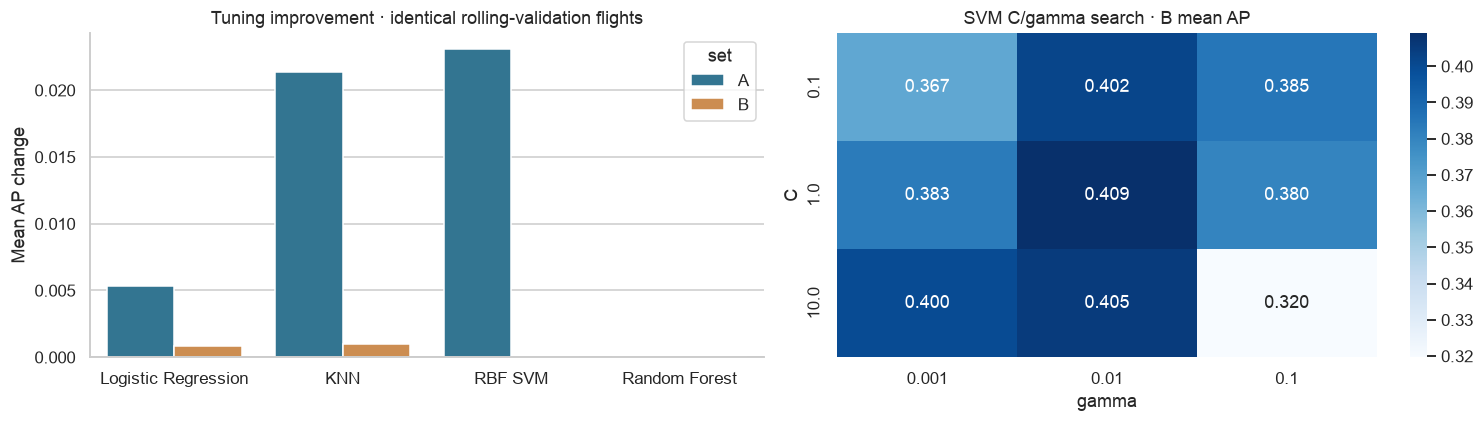

In [9]:
tuning_table=pd.DataFrame([{'model':NAMES[m],'set':fs,
 'baseline_cv_ap':evaluate(m,fs,'original','original',BASE_CHOICES[(m,fs)]['params'])['row']['mean_ap'],
 'tuned_cv_ap':v['row']['mean_ap'],'recipe':v['row']['recipe'],'params':json.dumps(v['row']['params'])}
 for (m,fs),v in chosen_tuning.items()])
tuning_table['gain']=tuning_table['tuned_cv_ap']-tuning_table['baseline_cv_ap']
table(tuning_table,index=False)
fig,axes=plt.subplots(1,2,figsize=(14,4))
sns.barplot(data=tuning_table,x='model',y='gain',hue='set',errorbar=None,ax=axes[0])
axes[0].set(title='Tuning improvement · identical rolling-validation flights',ylabel='Mean AP change',xlabel='')
svm_trials=pd.DataFrame([{'C':r['params']['C'],'gamma':r['params'].get('gamma','scale'),
                         'AP':r['mean_ap']} for r in runs if r['model_id']=='svm' and r['feature_set']=='B' and r['recipe']=='separate'])
sns.heatmap(svm_trials.pivot(index='C',columns='gamma',values='AP'),annot=True,fmt='.3f',cmap='Blues',ax=axes[1])
axes[1].set_title('SVM C/gamma search · B mean AP')
plot()

## Controlled feature-package comparison

All four models evaluate the same four B packages with their tuned settings held fixed. The common package maximizes mean AP across model families and validation folds. This is a staged search: it does not establish globally optimal features, and a combined gain cannot be attributed to one weather measurement.

The sequence tests the extra contribution of each family **after the previous families**. It is not a causal analysis. A raw correlation or a high feature-importance score would not replace these retraining comparisons.

logistic_regression/B/time/20,000 AP=0.4275 (separate; {'C': 0.03})


knn/B/time/20,000 AP=0.4066 (separate; {'n_neighbors': 101, 'weights': 'distance', 'metric': 'euclidean'})


svm/B/time/20,000 AP=0.4147 (original; {'C': 1.0})


random_forest/B/time/20,000 AP=0.4149 (original; {'max_depth': 16, 'min_samples_leaf': 5})


logistic_regression/B/time_flight/20,000 AP=0.4317 (separate; {'C': 0.03})


...

logistic_regression/B/time_flight_weather/20,000 AP=0.4453 (separate; {'C': 0.03})


knn/B/time_flight_weather/20,000 AP=0.4249 (separate; {'n_neighbors': 101, 'weights': 'distance', 'metric': 'euclidean'})


svm/B/time_flight_weather/20,000 AP=0.4229 (original; {'C': 1.0})


random_forest/B/time_flight_weather/20,000 AP=0.4334 (original; {'max_depth': 16, 'min_samples_leaf': 5})


Common selected B package: time_flight_weather
           model_id             package  mean_ap    ap_sd
logistic_regression            original 0.426390 0.009573
                knn            original 0.405584 0.034858
                svm            original 0.411562 0.045710
      random_forest            original 0.421533 0.037843
logistic_regression                time 0.427456 0.010021
                knn                time 0.406607 0.036809
                svm                time 0.414673 0.037767
      random_forest                time 0.414861 0.030972
logistic_regression         time_flight 0.431676 0.014785
                knn         time_flight 0.412190 0.037580
                svm         time_flight 0.417923 0.037449
      random_forest         time_flight 0.418603 0.031382
logistic_regression time_flight_weather 0.445339 0.020908
                knn time_flight_weather 0.424941 0.040716
                svm time_flight_weather 0.422941 0.045214
      random_forest time_

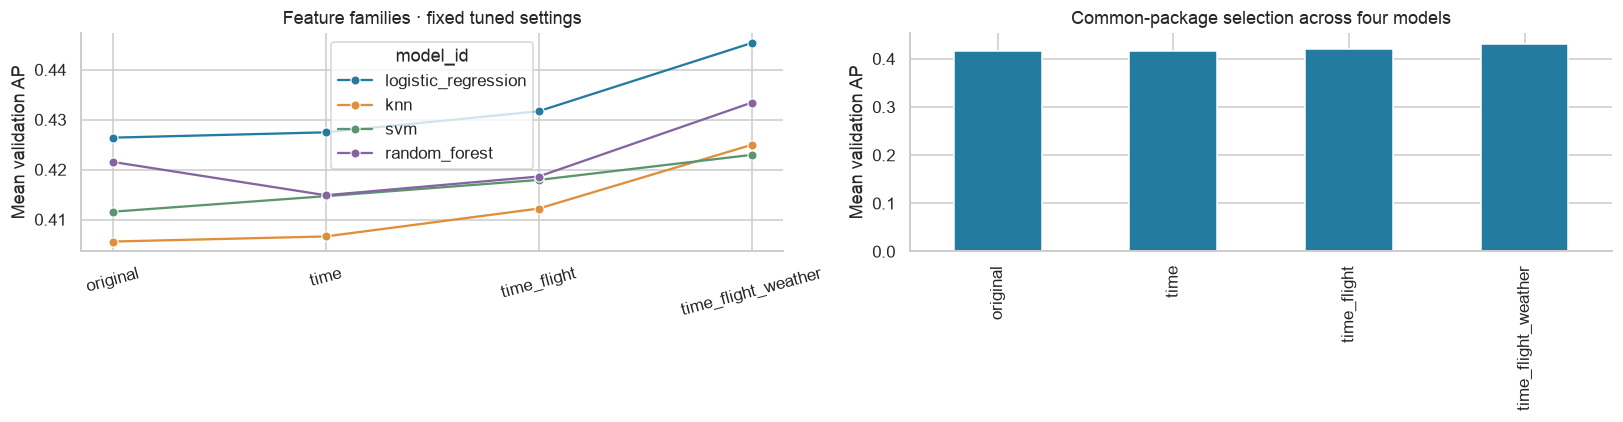

In [10]:
package_results={}
for package in PACKAGES_FEATURES:
    for m in NAMES:
        settings=chosen_tuning[(m,'B')]['row']
        package_results[(m,package)]=evaluate(m,'B',package,settings['recipe'],settings['params'])
package_table=pd.DataFrame([r['row'] for r in package_results.values()])
package_means=package_table.groupby('package',sort=False)['mean_ap'].mean().reindex(PACKAGES_FEATURES)
CHOSEN_PACKAGE=str(package_means.idxmax())
print('Common selected B package:',CHOSEN_PACKAGE)
table(package_table[['model_id','package','mean_ap','ap_sd']],index=False)
fig,axes=plt.subplots(1,2,figsize=(15,4))
sns.lineplot(data=package_table,x='package',y='mean_ap',hue='model_id',marker='o',ax=axes[0])
axes[0].tick_params(axis='x',rotation=15);axes[0].set(title='Feature families · fixed tuned settings',xlabel='',ylabel='Mean validation AP')
package_means.plot.bar(ax=axes[1]);axes[1].set(title='Common-package selection across four models',ylabel='Mean validation AP',xlabel='')
plot()

## Does doubling the fitting sample help?

Each 20k sample is contained in its 40k sample. Validation flights, feature package and settings stay fixed. The same size is selected for all eight A/B pipelines using their overall mean AP. Larger samples may help one model and hurt another; report both the score and runtime differences.

These are observed development differences, not a statistical guarantee. KNN's training score is not used because self-neighbours make it misleading.

logistic_regression/A/time_flight_weather/20,000 AP=0.4022 (separate; {'C': 0.01})


logistic_regression/A/time_flight_weather/40,000 AP=0.4003 (separate; {'C': 0.01})


logistic_regression/B/time_flight_weather/40,000 AP=0.4487 (separate; {'C': 0.03})


knn/A/time_flight_weather/20,000 AP=0.3841 (separate; {'n_neighbors': 101, 'weights': 'distance', 'metric': 'euclidean'})


knn/A/time_flight_weather/40,000 AP=0.3852 (separate; {'n_neighbors': 101, 'weights': 'distance', 'metric': 'euclidean'})


...

svm/B/time_flight_weather/40,000 AP=0.4282 (original; {'C': 1.0})


random_forest/A/time_flight_weather/20,000 AP=0.3917 (original; {'max_depth': 16, 'min_samples_leaf': 20})


random_forest/A/time_flight_weather/40,000 AP=0.3906 (original; {'max_depth': 16, 'min_samples_leaf': 20})


random_forest/B/time_flight_weather/40,000 AP=0.4426 (original; {'max_depth': 16, 'min_samples_leaf': 5})


Common selected training size: 40000
           model_id feature_set  training_rows  mean_ap  mean_fit_seconds
logistic_regression           A          20000 0.402171          0.061715
logistic_regression           A          40000 0.400338          0.123516
logistic_regression           B          20000 0.445339          0.158239
logistic_regression           B          40000 0.448726          0.322193
                knn           A          20000 0.384073          0.041201
                knn           A          40000 0.385209          0.076497
                knn           B          20000 0.424941          0.079773
                knn           B          40000 0.417453          0.155379
                svm           A          20000 0.345095          7.956226
                svm           A          40000 0.348455         51.120306
                svm           B          20000 0.422941         18.136016
                svm           B          40000 0.428245        191.272810
 

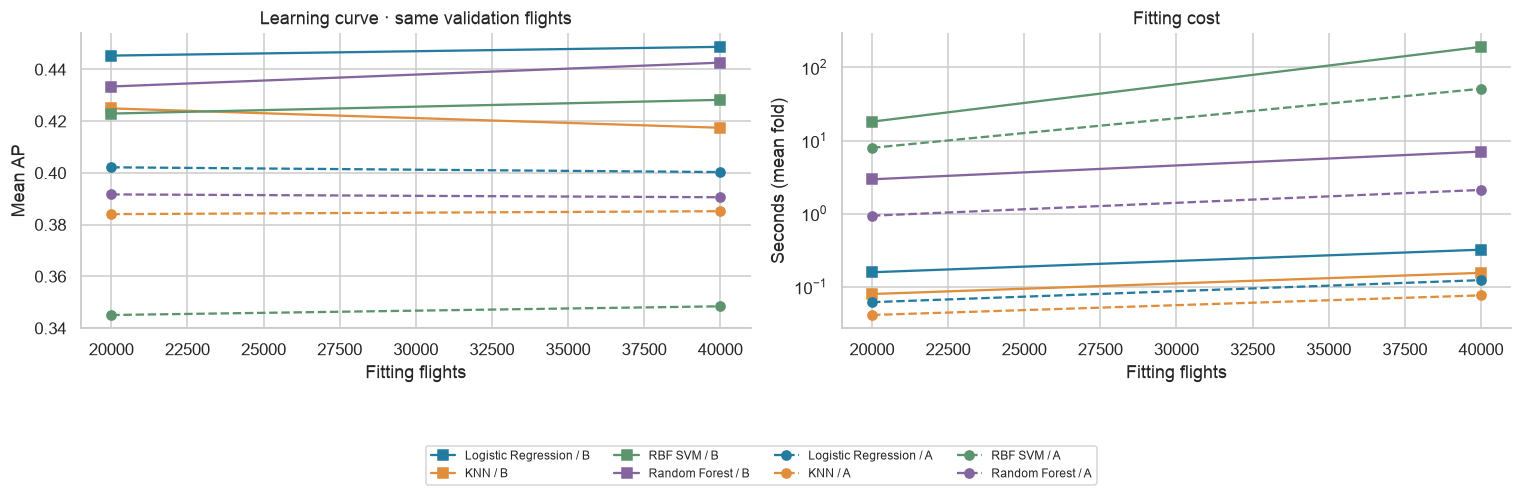

In [11]:
learning={}
for m in NAMES:
    for fs in ['A','B']:
        settings=chosen_tuning[(m,fs)]['row']
        for size in [20000,40000]:
            learning[(m,fs,size)]=evaluate(m,fs,CHOSEN_PACKAGE,settings['recipe'],settings['params'],size)
learning_table=pd.DataFrame([v['row'] for v in learning.values()])
size_means=learning_table.groupby('training_rows',sort=True)['mean_ap'].mean()
CHOSEN_SIZE=int(size_means.idxmax())
print('Common selected training size:',CHOSEN_SIZE)
table(learning_table[['model_id','feature_set','training_rows','mean_ap','mean_fit_seconds']],index=False)
fig,axes=plt.subplots(1,2,figsize=(14,4.5))
model_colors=dict(zip(NAMES,['#247BA0','#E08D3C','#5C946E','#8465A0']))
for (m,fs),block in learning_table.groupby(['model_id','feature_set'],sort=False):
    style={'color':model_colors[m],'linestyle':'--' if fs=='A' else '-',
           'marker':'o' if fs=='A' else 's','label':NAMES[m]+' / '+fs}
    axes[0].plot(block['training_rows'],block['mean_ap'],**style)
    axes[1].plot(block['training_rows'],block['mean_fit_seconds'],**style)
axes[0].set(title='Learning curve · same validation flights',xlabel='Fitting flights',ylabel='Mean AP')
axes[1].set(title='Fitting cost',xlabel='Fitting flights',ylabel='Seconds (mean fold)',yscale='log')
handles,labels=axes[0].get_legend_handles_labels()
fig.legend(handles,labels,loc='lower center',ncol=4,fontsize=8)
fig.tight_layout(rect=(0,.17,1,1))
plt.show()

## Freeze the final choices and warning thresholds

Model/set selection uses mean rolling-validation AP. The latest validation block (October–December) sets each warning threshold; pooling raw SVM scores from independently fitted folds would mix different score scales. F1 is primary. F0.5 is retained as a clearly labelled alternative operating policy.

The choices and their timestamp are saved **before** any fresh-test evaluation. Threshold transfer to the all-2025 refit is an assumption tested later; the fresh test must not be used to readjust it.

Frozen before fresh test: 2026-10-18T21:15:50.566255+00:00
Selected model: Logistic Regression /  B
           model_id feature_set policy  precision   recall       f1      f05   fp  fn
logistic_regression           A     F1   0.340856 0.691943 0.456726 0.379352 1694 390
logistic_regression           A   F0.5   0.425188 0.312006 0.359909 0.396427  534 871
logistic_regression           B     F1   0.370059 0.695103 0.482986 0.408239 1498 386
logistic_regression           B   F0.5   0.437145 0.425750 0.431373 0.434818  694 727
                knn           A     F1   0.323551 0.687994 0.440121 0.361891 1821 395
                knn           A   F0.5   0.351636 0.500790 0.413164 0.373909 1169 632
                knn           B     F1   0.339615 0.697472 0.456803 0.378450 1717 383
                knn           B   F0.5   0.358325 0.581359 0.443373 0.388104 1318 530
                svm           A     F1   0.253352 1.000000 0.404279 0.297826 3731   0
                svm           A   F0.5  

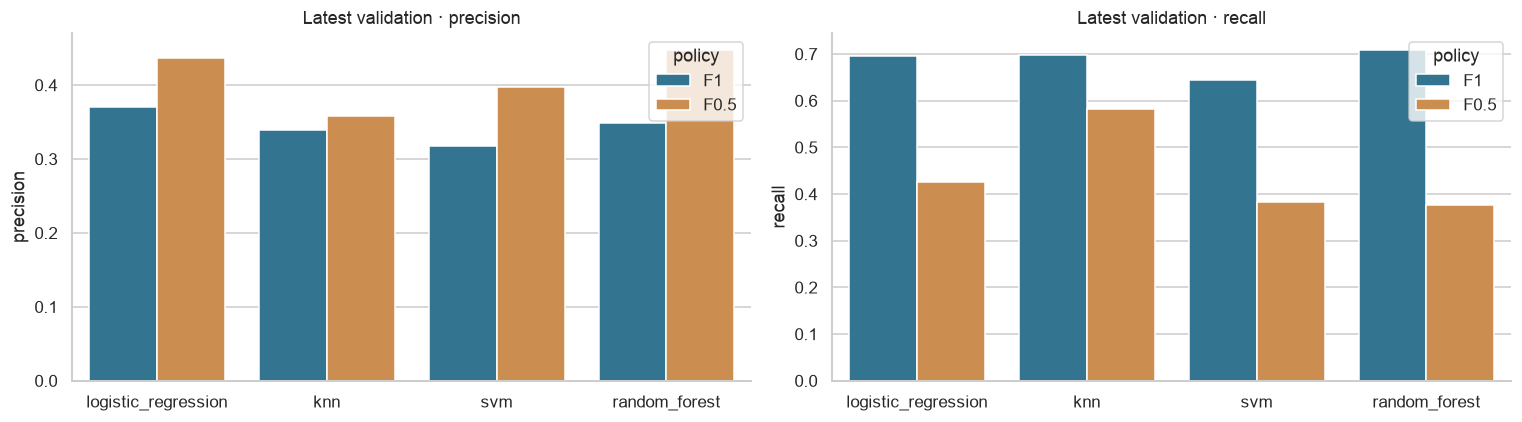

In [12]:
choices=[];operating=[]
for m in NAMES:
    for fs in ['A','B']:
        item=learning[(m,fs,CHOSEN_SIZE)];row=item['row']
        latest=working.loc[item['latest']['ids']];y=latest['delayed_departure'].to_numpy();s=item['latest']['scores']
        thresholds={name:best_threshold(y,s,beta) for name,beta in [('F1',1.),('F0.5',.5)]}
        choice=dict(row,columns=columns_for(fs,CHOSEN_PACKAGE),thresholds=thresholds)
        choices.append(choice)
        for policy,t in thresholds.items():operating.append({'model_id':m,'feature_set':fs,'policy':policy,**measures(y,s,t)})
selected=max(choices,key=lambda r:r['mean_ap'])
cohort_hashes={fold:{'train20k':fingerprint(working.loc[c['train'][20000]]),
 'train40k':fingerprint(working.loc[c['train'][40000]]),
 'validation':fingerprint(working.loc[c['validation']])} for fold,c in cohorts.items()}
selection={'run_id':RUN_ID,'frozen_at_utc':datetime.now(timezone.utc).isoformat(),
 'protocol_sha256':PROTOCOL_SHA,'feature_input_sha256':sha(ROOT/PREP['output']),
 'helper_sha256':sha(ROOT/'scripts/improvement_features.py'),'weather_audit':weather_audit,
 'cohort_hashes':cohort_hashes,'refit_cohort_fingerprint':fingerprint(working.loc[final_ids[CHOSEN_SIZE]]),
 'chosen_feature_package':CHOSEN_PACKAGE,'chosen_training_rows':CHOSEN_SIZE,
 'selected_model_id':selected['model_id'],'selected_feature_set':selected['feature_set'],
 'choices':choices,'development_runs':runs,'latest_validation_operating_points':operating,
 'test_outcomes_loaded':False,'test_start':'2026-04-01','test_end':'2026-06-30','test_rows':10000,
 'threshold_primary':'F1','packages':PACKAGES,
 'availability_note':'Historical schedule and report/outcome availability remain assumptions; seven-day outcome lag retained.'}
save_json(OUT/'selection.json',selection)
SELECTION_SHA=sha(OUT/'selection.json')
print('Frozen before fresh test:',selection['frozen_at_utc'])
print('Selected model:',NAMES[selected['model_id']],'/ ',selected['feature_set'])
operating_table=pd.DataFrame(operating)
table(operating_table[['model_id','feature_set','policy','precision','recall','f1','f05','fp','fn']],index=False)
fig,axes=plt.subplots(1,2,figsize=(14,4))
b=operating_table.loc[operating_table['feature_set'].eq('B')]
for metric,ax in zip(['precision','recall'],axes):
    sns.barplot(data=b,x='model_id',y=metric,hue='policy',errorbar=None,ax=ax)
    ax.set(title='Latest validation · '+metric,xlabel='',ylabel=metric)
plot()

## Final refit on all twelve months of 2025

Only now do we refit the eight frozen pipelines on the chosen common sample from all twelve months. Standard scikit-learn objects are saved, so loading the bundle does not require custom notebook classes.

This notebook does not assert a new test improvement. Notebook 05 compares the frozen original and improved pipelines on the **same** new flights; scores from Q1 and Q2 must not be subtracted as if they were a controlled comparison.

In [13]:
refit=working.loc[final_ids[CHOSEN_SIZE]]
final_models={}
for choice in choices:
    m,fs=choice['model_id'],choice['feature_set'];columns=choice['columns']
    pipeline=make_pipeline(m,columns,choice['recipe'],choice['params'])
    start=perf_counter();pipeline.fit(refit[columns],refit['delayed_departure']);elapsed=perf_counter()-start
    classifier=pipeline.named_steps['classifier']
    if isinstance(classifier,SVC):assert classifier.fit_status_==0
    if isinstance(classifier,LogisticRegression):assert classifier.n_iter_.max()<classifier.max_iter
    final_models[m+'__'+fs]={'pipeline':pipeline,'columns':columns,'threshold':choice['thresholds']['F1'],
        'thresholds':choice['thresholds'],'feature_set':fs,'model_id':m,'fit_seconds':elapsed,
        'score_type':'decision_function' if m=='svm' else 'uncalibrated_probability'}
    print(f'Refit {m}/{fs}: {len(refit):,} flights; {elapsed:.2f}s',flush=True)
bundle={'run_id':RUN_ID,'selection_sha256':SELECTION_SHA,'protocol_sha256':PROTOCOL_SHA,
        'models':final_models,'selected_model_id':selected['model_id'],'selected_feature_set':selected['feature_set'],
        'training_rows':CHOSEN_SIZE,'feature_package':CHOSEN_PACKAGE,'selection':selection}
model_path=ROOT/'models/improved_flight_delay_models.joblib'
joblib.dump(bundle,model_path,compress=3)
assert all(sha(ROOT/p)==v for p,v in protected.items()),'A protected baseline file changed.'
summary={'run_id':RUN_ID,'selection_sha256':SELECTION_SHA,'model_sha256':sha(model_path),
 'model_path':model_path.relative_to(ROOT).as_posix(),'completed_at_utc':datetime.now(timezone.utc).isoformat(),
 'baseline_files_unchanged':True,'fresh_test_evaluated':False,'total_distinct_cv_configurations':len(runs),
 'cv_fit_count':len(runs)*len(FOLDS),'chosen_feature_package':CHOSEN_PACKAGE,'chosen_training_rows':CHOSEN_SIZE}
save_json(OUT/'development_summary.json',summary)
print('Saved',model_path.relative_to(ROOT))
print('Development complete. Next: frozen comparison on April–June 2026 in notebook 05.')

Refit logistic_regression/A: 40,000 flights; 0.12s


Refit logistic_regression/B: 40,000 flights; 0.33s


Refit knn/A: 40,000 flights; 0.08s


Refit knn/B: 40,000 flights; 0.16s


Refit svm/A: 40,000 flights; 52.41s


Refit svm/B: 40,000 flights; 192.55s


Refit random_forest/A: 40,000 flights; 2.13s


Refit random_forest/B: 40,000 flights; 7.21s


Saved models/improved_flight_delay_models.joblib
Development complete. Next: frozen comparison on April–June 2026 in notebook 05.


## Reading the findings

- AP changes measure ranking quality; changing a warning threshold cannot increase AP.
- F1 and F0.5 reflect different precision/recall priorities. A lower false-warning count can come with more missed delays.
- Model settings, feature packages and sample size were selected using development data. Only the later frozen test provides confirmation.
- We still cannot observe last-minute aircraft assignments, confirmed report receipt times or all operational causes of disruption. Better tuning does not remove those information limits.

Method references: [joint SVM tuning](https://scikit-learn.org/stable/auto_examples/svm/plot_rbf_parameters.html), [temporal validation](https://scikit-learn.org/stable/modules/cross_validation.html#time-series-split), [cyclical feature engineering](https://scikit-learn.org/stable/auto_examples/applications/plot_cyclical_feature_engineering.html), and [threshold selection](https://scikit-learn.org/stable/modules/classification_threshold.html). Full project-specific reasoning is in `reports/MODEL_IMPROVEMENT_RESEARCH.md`.